# Rossmann Store Sales — Exploratory Data Analysis

Forecasting-oriented EDA for daily store sales.

**Goal:** understand the target, time structure, demand drivers, store heterogeneity, and feature availability/leakage before modeling.

**Sections**
1. Setup & data health
2. Target understanding
3. Time patterns
4. Demand drivers
5. Store heterogeneity
6. Leakage & availability
7. Simple baselines
8. EDA conclusions

## 1. Setup & data health

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Resolve data dir whether the kernel cwd is repo root or notebooks/
_cwd = Path.cwd()
DATA_DIR = _cwd / "data" if (_cwd / "data").exists() else _cwd.parent / "data"
assert DATA_DIR.exists(), f"Could not find data directory from {_cwd}"

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", low_memory=False, parse_dates=["Date"])
test = pd.read_csv(DATA_DIR / "test.csv", low_memory=False, parse_dates=["Date"])
store = pd.read_csv(DATA_DIR / "store.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("train:", train.shape, train["Date"].min().date(), "→", train["Date"].max().date())
print("test :", test.shape, test["Date"].min().date(), "→", test["Date"].max().date())
print("store:", store.shape)
print("sample_submission:", sample_sub.shape)

train: (1017209, 9) 2013-01-01 → 2015-07-31
test : (41088, 8) 2015-08-01 → 2015-09-17
store: (1115, 10)
sample_submission: (41088, 2)


In [3]:
display(train.head())
display(test.head())
display(store.head())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.00,1,0,0
1,2,3,4,2015-09-17,1.00,1,0,0
2,3,7,4,2015-09-17,1.00,1,0,0
3,4,8,4,2015-09-17,1.00,1,0,0
4,5,9,4,2015-09-17,1.00,1,0,0


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN


In [5]:
def missing_summary(df: pd.DataFrame, name: str) -> pd.DataFrame:
    out = (
        df.isna()
        .sum()
        .rename("n_missing")
        .to_frame()
        .assign(pct=lambda x: 100 * x["n_missing"] / len(df))
        .query("n_missing > 0")
        .sort_values("n_missing", ascending=False)
    )
    print(f"{name}: {len(out)} columns with missing values")
    return out

display(missing_summary(train, "train"))
display(missing_summary(test, "test"))
display(missing_summary(store, "store"))

train: 0 columns with missing values


,n_missing,pct


test: 1 columns with missing values


,n_missing,pct
Open,11,0.03


store: 6 columns with missing values


,n_missing,pct
Promo2SinceWeek,544,48.79
Promo2SinceYear,544,48.79
PromoInterval,544,48.79
CompetitionOpenSinceMonth,354,31.75
CompetitionOpenSinceYear,354,31.75
CompetitionDistance,3,0.27


In [6]:
# Join store attributes
train_m = train.merge(store, on="Store", how="left", validate="many_to_one")
test_m = test.merge(store, on="Store", how="left", validate="many_to_one")

assert train_m["Store"].isna().sum() == 0
assert test_m["Store"].isna().sum() == 0

# Basic integrity checks
dup_train = train.duplicated(subset=["Store", "Date"]).sum()
dup_test = test.duplicated(subset=["Store", "Date"]).sum()
closed_nonzero = ((train["Open"] == 0) & (train["Sales"] != 0)).sum()
open_zero = ((train["Open"] == 1) & (train["Sales"] == 0)).sum()

print(f"Duplicate (Store, Date) in train: {dup_train}")
print(f"Duplicate (Store, Date) in test : {dup_test}")
print(f"Closed days with Sales != 0     : {closed_nonzero}")
print(f"Open days with Sales == 0       : {open_zero}")
print(f"Unique stores train/test/store  : {train.Store.nunique()} / {test.Store.nunique()} / {store.Store.nunique()}")
print(f"Test stores missing from train  : {len(set(test.Store) - set(train.Store))}")
print(f"Train stores missing from test  : {len(set(train.Store) - set(test.Store))}")
print(f"Test Open nulls                 : {test['Open'].isna().sum()}")

Duplicate (Store, Date) in train: 0
Duplicate (Store, Date) in test : 0
Closed days with Sales != 0     : 0
Open days with Sales == 0       : 54
Unique stores train/test/store  : 1115 / 856 / 1115
Test stores missing from train  : 0
Train stores missing from test  : 259
Test Open nulls                 : 11


**Data-health takeaways**
- Train has no missing values; test has a few missing `Open` values that need a rule at inference.
- Store master has substantial missingness in competition open dates and Promo2 fields.
- No `(Store, Date)` duplicates; closed days never have non-zero sales.
- All test stores appear in train; 259 train stores are absent from the test window.

## 2. Target understanding

In [7]:
sales_desc = train["Sales"].describe(percentiles=[0.5, 0.9, 0.99])
open_sales = train.loc[train["Open"] == 1, "Sales"]

print("All days")
display(sales_desc.to_frame("Sales"))
print("Open days only")
display(open_sales.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("Sales"))

zero_share = (train["Sales"] == 0).mean()
closed_share = (train["Open"] == 0).mean()
print(f"Share Sales==0: {zero_share:.1%}")
print(f"Share Open==0 : {closed_share:.1%}")

All days


,Sales
count,"1,017,209.00"
mean,"5,773.82"
std,"3,849.93"
min,0.00
50%,"5,744.00"
90%,"10,288.00"
99%,"17,160.00"
max,"41,551.00"


Open days only


,Sales
count,"844,392.00"
mean,"6,955.51"
std,"3,104.21"
min,0.00
50%,"6,369.00"
90%,"10,771.00"
99%,"17,789.00"
max,"41,551.00"


Share Sales==0: 17.0%
Share Open==0 : 17.0%


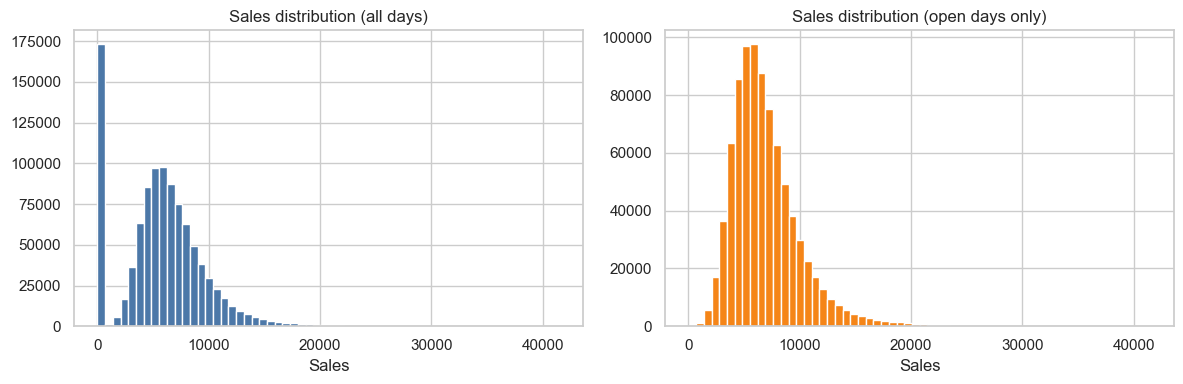

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["Sales"], bins=60, color="#4C78A8", edgecolor="white")
axes[0].set_title("Sales distribution (all days)")
axes[0].set_xlabel("Sales")

axes[1].hist(open_sales, bins=60, color="#F58518", edgecolor="white")
axes[1].set_title("Sales distribution (open days only)")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.show()

Distribution of sales seems log-normal. We will log transform the sales data to get it normally distributed.

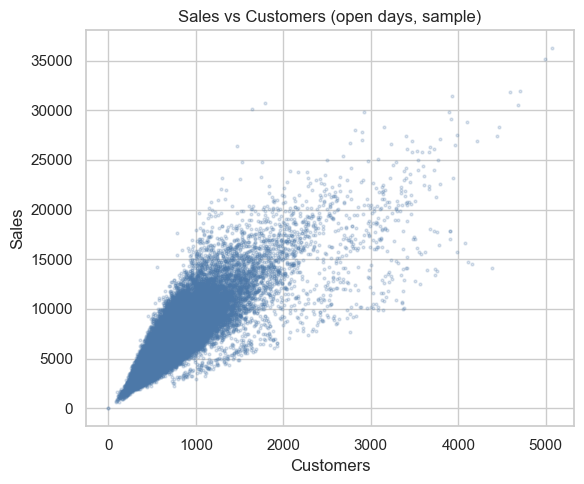

Pearson correlation (open days): 0.824
Note: Customers is historical-only and must not be used as a test feature.


In [9]:
open_df = train.loc[train["Open"] == 1].copy()

fig, ax = plt.subplots(figsize=(6, 5))
sample = open_df.sample(n=min(40_000, len(open_df)), random_state=RANDOM_SEED)
ax.scatter(sample["Customers"], sample["Sales"], s=4, alpha=0.2, color="#4C78A8")
ax.set_xlabel("Customers")
ax.set_ylabel("Sales")
ax.set_title("Sales vs Customers (open days, sample)")
plt.tight_layout()
plt.show()

corr = open_df["Sales"].corr(open_df["Customers"])
print(f"Pearson correlation (open days): {corr:.3f}")
print("Note: Customers is historical-only and must not be used as a test feature.")

## 3. Time patterns

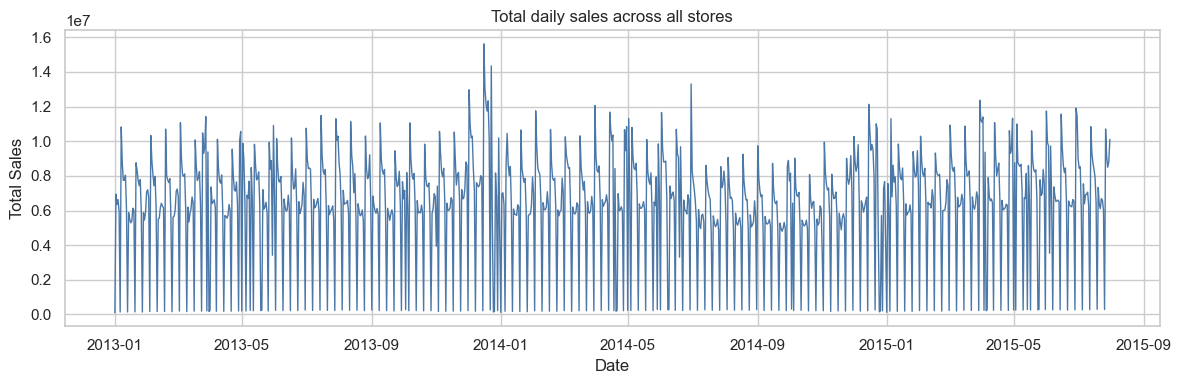

In [10]:
daily = (
    train.groupby("Date", as_index=False)
    .agg(Sales=("Sales", "sum"), OpenStores=("Open", "sum"), Stores=("Store", "nunique"))
    .sort_values("Date")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily["Date"], daily["Sales"], color="#4C78A8", linewidth=1)
ax.set_title("Total daily sales across all stores")
ax.set_xlabel("Date")
ax.set_ylabel("Total Sales")
plt.tight_layout()
plt.show()

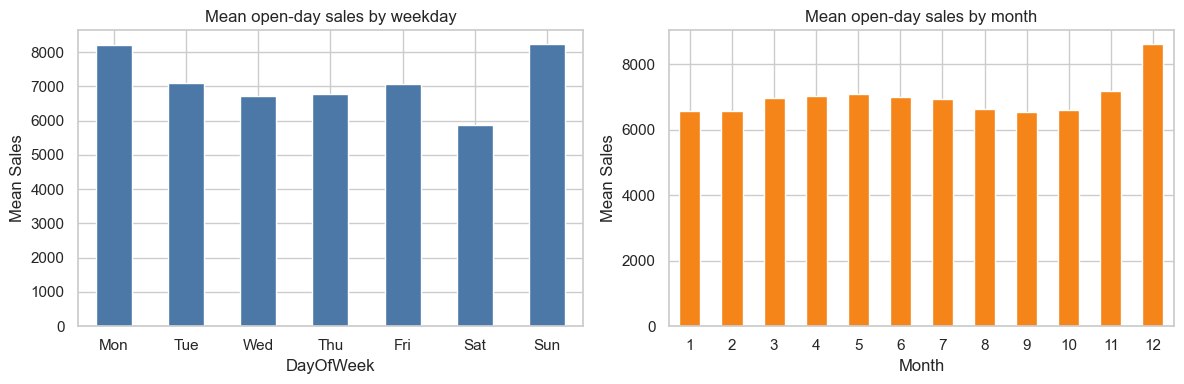

In [11]:
dow_map = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
dow = (
    open_df.groupby("DayOfWeek")["Sales"]
    .mean()
    .rename(index=dow_map)
    .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dow.plot(kind="bar", ax=axes[0], color="#4C78A8", rot=0)
axes[0].set_title("Mean open-day sales by weekday")
axes[0].set_xlabel("DayOfWeek")
axes[0].set_ylabel("Mean Sales")

monthly = open_df.assign(Month=open_df["Date"].dt.month).groupby("Month")["Sales"].mean()
monthly.plot(kind="bar", ax=axes[1], color="#F58518", rot=0)
axes[1].set_title("Mean open-day sales by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean Sales")

plt.tight_layout()
plt.show()

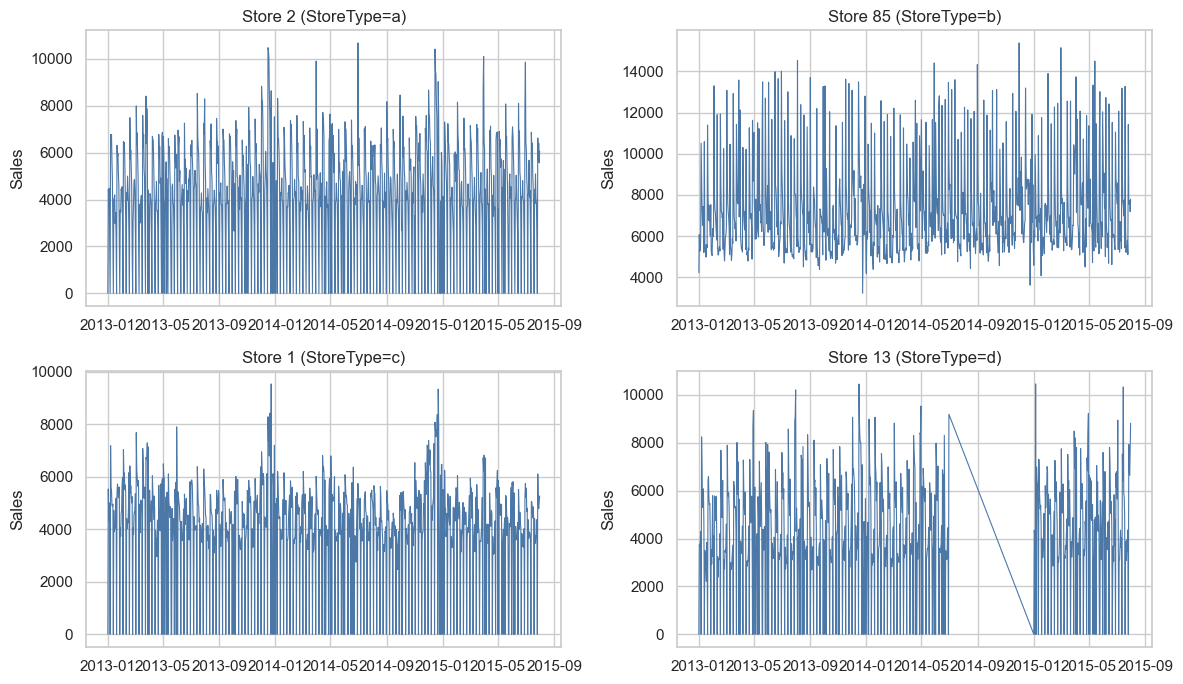

In [12]:
# Example store series by StoreType
examples = (
    train_m.groupby("StoreType")["Store"]
    .min()  # deterministic pick
    .to_dict()
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=False)
axes = axes.ravel()

for ax, (stype, store_id) in zip(axes, examples.items()):
    s = train_m.loc[train_m["Store"] == store_id, ["Date", "Sales"]].sort_values("Date")
    ax.plot(s["Date"], s["Sales"], linewidth=0.8, color="#4C78A8")
    ax.set_title(f"Store {store_id} (StoreType={stype})")
    ax.set_ylabel("Sales")

plt.tight_layout()
plt.show()

In [13]:
print("Train window:", train["Date"].min().date(), "→", train["Date"].max().date())
print("Test window :", test["Date"].min().date(), "→", test["Date"].max().date())
print("Forecast horizon (days):", (test["Date"].max() - test["Date"].min()).days + 1)
print("Gap between train end and test start (days):", (test["Date"].min() - train["Date"].max()).days)

Train window: 2013-01-01 → 2015-07-31
Test window : 2015-08-01 → 2015-09-17
Forecast horizon (days): 48
Gap between train end and test start (days): 1


## 4. Demand drivers

In [14]:
def mean_sales_by(df: pd.DataFrame, col: str) -> pd.Series:
    return df.groupby(col)["Sales"].mean().sort_values(ascending=False)

open_m = train_m.loc[train_m["Open"] == 1].copy()

driver_tables = {
    "Promo": mean_sales_by(open_m, "Promo"),
    "StateHoliday": mean_sales_by(open_m, "StateHoliday"),
    "SchoolHoliday": mean_sales_by(open_m, "SchoolHoliday"),
    "StoreType": mean_sales_by(open_m, "StoreType"),
    "Assortment": mean_sales_by(open_m, "Assortment"),
    "Promo2": mean_sales_by(open_m, "Promo2"),
}

for name, series in driver_tables.items():
    print(f"\nMean open-day Sales by {name}")
    display(series.to_frame("mean_Sales"))


Mean open-day Sales by Promo


,mean_Sales
Promo,
1,"8,228.28"
0,"5,929.41"



Mean open-day Sales by StateHoliday


,mean_Sales
StateHoliday,
b,"9,887.89"
c,"9,743.75"
a,"8,487.47"
0,"6,953.52"



Mean open-day Sales by SchoolHoliday


,mean_Sales
SchoolHoliday,
1,"7,200.18"
0,"6,896.78"


... (2 outputs left out)


Mean open-day Sales by Assortment


,mean_Sales
Assortment,
b,"8,639.35"
c,"7,300.53"
a,"6,621.02"



Mean open-day Sales by Promo2


,mean_Sales
Promo2,
0,"7,350.56"
1,"6,558.39"


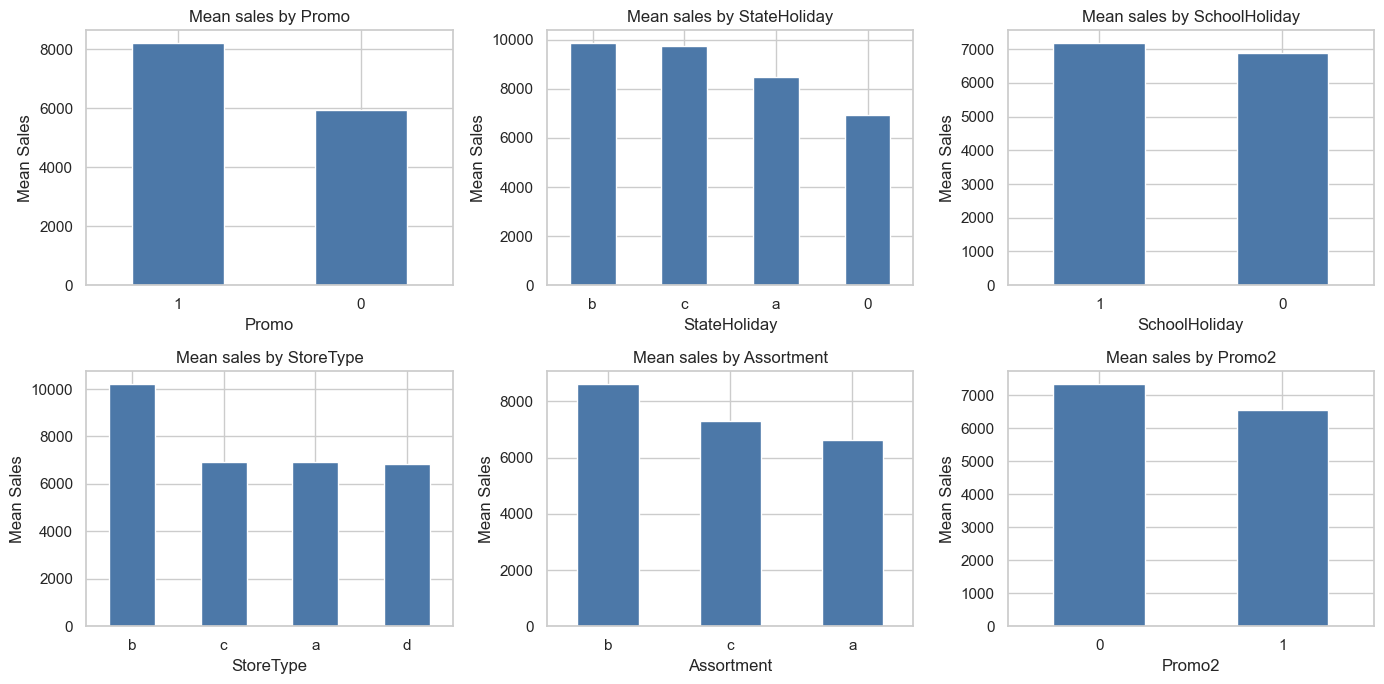

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (name, series) in zip(axes, driver_tables.items()):
    series.plot(kind="bar", ax=ax, color="#4C78A8", rot=0)
    ax.set_title(f"Mean sales by {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Mean Sales")

plt.tight_layout()
plt.show()

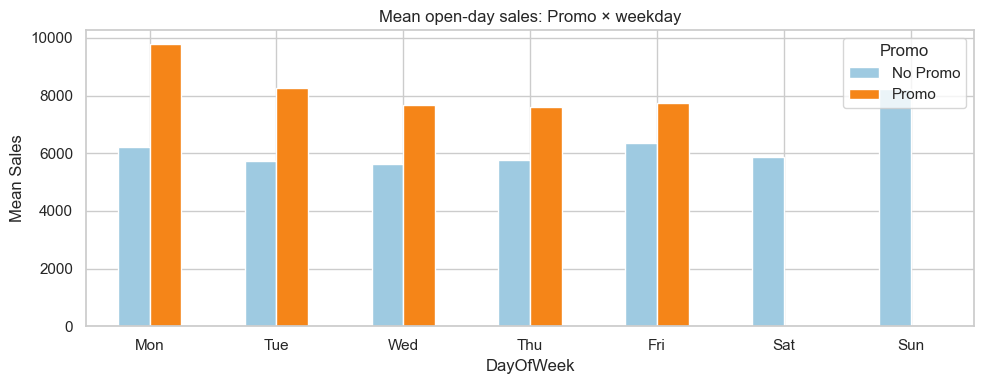

Average promo lift (open days): 38.8%


In [15]:
# Promo × weekday interaction
promo_dow = (
    open_m.groupby(["DayOfWeek", "Promo"])["Sales"]
    .mean()
    .unstack("Promo")
    .rename(columns={0: "No Promo", 1: "Promo"})
    .rename(index=dow_map)
    .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
)

fig, ax = plt.subplots(figsize=(10, 4))
promo_dow.plot(kind="bar", ax=ax, rot=0, color=["#9ECAE1", "#F58518"])
ax.set_title("Mean open-day sales: Promo × weekday")
ax.set_xlabel("DayOfWeek")
ax.set_ylabel("Mean Sales")
ax.legend(title="Promo")
plt.tight_layout()
plt.show()

lift = open_m.groupby("Promo")["Sales"].mean()
if 0 in lift.index and 1 in lift.index and lift.loc[0] > 0:
    print(f"Average promo lift (open days): {(lift.loc[1] / lift.loc[0] - 1):.1%}")

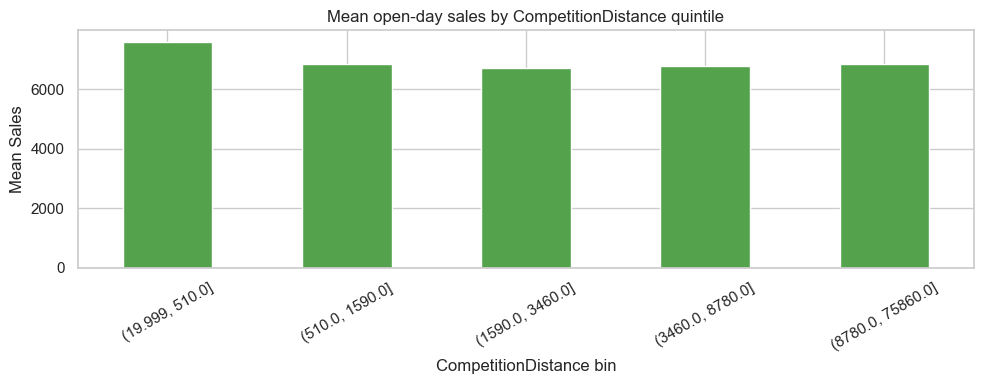

,mean_Sales
CompetitionDistanceBin,
"(19.999, 510.0]","7,596.01"
"(510.0, 1590.0]","6,836.67"
"(1590.0, 3460.0]","6,729.70"
"(3460.0, 8780.0]","6,793.14"
"(8780.0, 75860.0]","6,836.50"


In [16]:
# Competition distance bins
comp = open_m.dropna(subset=["CompetitionDistance"]).copy()
comp["CompetitionDistanceBin"] = pd.qcut(
    comp["CompetitionDistance"], q=5, duplicates="drop"
)

comp_means = comp.groupby("CompetitionDistanceBin", observed=True)["Sales"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
comp_means.plot(kind="bar", ax=ax, color="#54A24B", rot=30)
ax.set_title("Mean open-day sales by CompetitionDistance quintile")
ax.set_xlabel("CompetitionDistance bin")
ax.set_ylabel("Mean Sales")
plt.tight_layout()
plt.show()
display(comp_means.to_frame("mean_Sales"))

## 5. Store heterogeneity

In [17]:
store_stats = (
    open_m.groupby("Store")
    .agg(
        mean_Sales=("Sales", "mean"),
        std_Sales=("Sales", "std"),
        median_Sales=("Sales", "median"),
        n_days=("Sales", "size"),
        StoreType=("StoreType", "first"),
        Assortment=("Assortment", "first"),
    )
    .assign(cv=lambda x: x["std_Sales"] / x["mean_Sales"])
    .sort_values("mean_Sales", ascending=False)
)

display(store_stats.head(10))
display(store_stats["mean_Sales"].describe().to_frame("store_mean_Sales"))

top10_share = store_stats.head(10)["mean_Sales"].sum() / store_stats["mean_Sales"].sum()
print(f"Share of total mean-sales mass in top 10 stores: {top10_share:.1%}")

,mean_Sales,std_Sales,median_Sales,n_days,StoreType,Assortment,cv
Store,,,,,,,
817,"21,757.48","4,674.80","21,872.00",784,a,a,0.21
262,"20,718.52","4,668.88","19,415.50",942,b,a,0.23
1114,"20,666.56","3,452.94","20,412.50",784,a,c,0.17
251,"19,123.07","3,547.64","18,566.00",779,a,c,0.19
842,"18,574.80","3,788.99","18,330.00",622,d,c,0.20
513,"18,179.09","3,284.60","17,787.00",784,a,a,0.18
562,"17,969.56","2,931.93","18,029.50",942,b,c,0.16
788,"17,961.91","3,150.65","17,494.00",784,a,c,0.18
383,"17,294.72","2,785.81","17,039.50",780,a,c,0.16


,store_mean_Sales
count,"1,115.00"
mean,"6,934.21"
std,"2,383.91"
min,"2,703.74"
25%,"5,322.30"
50%,"6,589.95"
75%,"7,964.20"
max,"21,757.48"


Share of total mean-sales mass in top 10 stores: 2.4%


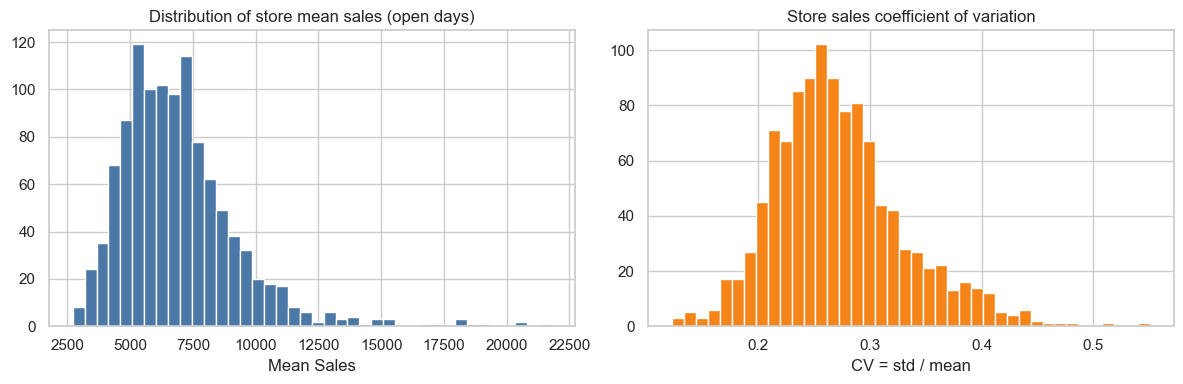

Mean open-day sales by StoreType


,count,mean,50%,std
StoreType,,,,
a,602.00,"6,912.54","6,481.22","2,587.43"
b,17.00,"10,110.78","9,744.60","4,594.00"
c,148.00,"6,917.20","6,645.84","2,173.69"
d,348.00,"6,823.74","6,695.22","1,779.63"


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(store_stats["mean_Sales"], bins=40, color="#4C78A8", edgecolor="white")
axes[0].set_title("Distribution of store mean sales (open days)")
axes[0].set_xlabel("Mean Sales")

axes[1].hist(store_stats["cv"].dropna(), bins=40, color="#F58518", edgecolor="white")
axes[1].set_title("Store sales coefficient of variation")
axes[1].set_xlabel("CV = std / mean")

plt.tight_layout()
plt.show()

print("Mean open-day sales by StoreType")
display(store_stats.groupby("StoreType")["mean_Sales"].describe()[["count", "mean", "50%", "std"]])

Low CV: sales are fairly steady day to day -> easier to forecast.

High CV: sales sqing a lot vs the usual level -> harder to forecast; promos/holidays/weekends may dominate.

In [19]:
train_only = sorted(set(train["Store"]) - set(test["Store"]))
print(f"Stores in train but not test: {len(train_only)}")
print("Examples:", train_only[:15])

Stores in train but not test: 259
Examples: [2, 4, 5, 6, 17, 18, 26, 28, 34, 37, 44, 54, 55, 57, 59]


## 6. Leakage & availability

In [20]:
availability = pd.DataFrame(
    [
        {"feature": "Store / Date / DayOfWeek", "status": "OK at forecast time", "notes": "Calendar identity"},
        {"feature": "Open", "status": "Mostly OK / needs rule", "notes": "Planned openings; 11 nulls in test"},
        {"feature": "Promo", "status": "OK at forecast time", "notes": "Assumed known from promo calendar"},
        {"feature": "StateHoliday / SchoolHoliday", "status": "OK at forecast time", "notes": "Assumed known from holiday calendar"},
        {"feature": "StoreType / Assortment / Promo2*", "status": "OK (store master)", "notes": "Static / slowly changing"},
        {"feature": "CompetitionDistance / open dates", "status": "OK but incomplete", "notes": "Many missing open-since fields"},
        {"feature": "Customers", "status": "Leakage if used for test", "notes": "Only known after the day ends"},
        {"feature": "Lag / rolling sales features", "status": "OK if time-aware", "notes": "Must use only past dates in validation"},
        {"feature": "Same-day Sales", "status": "Target only", "notes": "Never available as a feature"},
    ]
)
display(availability)

,feature,status,notes
0,Store / Date / DayOfWeek,OK at forecast time,Calendar identity
1,Open,Mostly OK / needs rule,Planned openings; 11 nulls in test
2,Promo,OK at forecast time,Assumed known from promo calendar
3,StateHoliday / SchoolHoliday,OK at forecast time,Assumed known from holiday calendar
4,StoreType / Assortment / Promo2*,OK (store master),Static / slowly changing
5,CompetitionDistance / open dates,OK but incomplete,Many missing open-since fields
6,Customers,Leakage if used for test,Only known after the day ends
7,Lag / rolling sales features,OK if time-aware,Must use only past dates in validation
8,Same-day Sales,Target only,Never available as a feature


**Validation implication:** use a time-based holdout (e.g. last 6 weeks of train) rather than random row splits, so feature availability matches deployment.

## 7. Simple baselines

In [21]:
def rmspe(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Official-style RMSPE; ignores zero-sales days."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    return float(np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)))


def mape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])))


def bias(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return float(np.mean(y_pred[mask] - y_true[mask]))

In [22]:
# Time-based holdout: last 6 weeks of train (~ competition horizon)
cutoff = train["Date"].max() - pd.Timedelta(days=42)
hist = train.loc[train["Date"] <= cutoff].copy()
holdout = train.loc[train["Date"] > cutoff].copy()

print("History:", hist["Date"].min().date(), "→", hist["Date"].max().date(), f"({len(hist):,} rows)")
print("Holdout:", holdout["Date"].min().date(), "→", holdout["Date"].max().date(), f"({len(holdout):,} rows)")

# Baseline A: store open-day median sales; 0 if closed
store_median = (
    hist.loc[hist["Open"] == 1]
    .groupby("Store")["Sales"]
    .median()
)
pred_median = holdout["Store"].map(store_median)
pred_median = pred_median.fillna(pred_median.median())
pred_median = np.where(holdout["Open"] == 0, 0.0, pred_median)

# Baseline B: same store + weekday mean from history; 0 if closed
store_dow_mean = (
    hist.loc[hist["Open"] == 1]
    .groupby(["Store", "DayOfWeek"])["Sales"]
    .mean()
)
pred_dow = holdout.set_index(["Store", "DayOfWeek"]).index.map(store_dow_mean)
pred_dow = pd.Series(pred_dow, index=holdout.index).fillna(holdout["Store"].map(store_median))
pred_dow = pred_dow.fillna(pred_dow.median())
pred_dow = np.where(holdout["Open"] == 0, 0.0, pred_dow)

# Baseline C: last week's same weekday sales (lag 7), fallback to store median
hist_key = hist.set_index(["Store", "Date"])["Sales"]
lag_dates = holdout["Date"] - pd.Timedelta(days=7)
lag_idx = pd.MultiIndex.from_arrays([holdout["Store"].to_numpy(), lag_dates.to_numpy()])
pred_lag7 = pd.Series(hist_key.reindex(lag_idx).to_numpy(), index=holdout.index)
# if lag falls in holdout itself, pull from full train history up to that date via hist only;
# remaining nulls -> store median
pred_lag7 = pred_lag7.fillna(holdout["Store"].map(store_median)).fillna(store_median.median())
pred_lag7 = np.where(holdout["Open"] == 0, 0.0, pred_lag7)

baselines = {
    "store_open_median": pred_median,
    "store_weekday_mean": pred_dow,
    "lag7_same_weekday": pred_lag7,
}

rows = []
y = holdout["Sales"].to_numpy()
for name, pred in baselines.items():
    rows.append(
        {
            "baseline": name,
            "RMSPE": rmspe(y, pred),
            "MAPE": mape(y, pred),
            "bias": bias(y, pred),
        }
    )

baseline_results = pd.DataFrame(rows).sort_values("RMSPE")
display(baseline_results)

History: 2013-01-01 → 2015-06-19 (970,379 rows)
Holdout: 2015-06-20 → 2015-07-31 (46,830 rows)


,baseline,RMSPE,MAPE,bias
1,store_weekday_mean,0.24,0.19,-36.24
0,store_open_median,0.31,0.22,-294.60
2,lag7_same_weekday,0.35,0.25,-87.57


## 8. EDA conclusions

### What we learned
- Sales are strongly right-skewed; closed days create a large mass of zeros and should be handled explicitly.
- Clear weekly seasonality and meaningful promo effects; holidays and store attributes also shift demand.
- Stores differ a lot in level and volatility — a global model needs store identity or strong store features.
- `Customers` tracks sales closely but is not available for the test horizon.
- Competition / Promo2 metadata is useful but incomplete.

### Modeling implications
- Use **time-based validation** (~last 6 weeks), not random splits.
- Force / hard-code **0 sales when Open=0**; impute rare missing `Open` in test.
- Priority features: store id/type, weekday, promo, holidays, seasonality, lag/rolling sales, competition distance.
- Beat the strongest simple baseline above before claiming model value (Forecast Value Add).

### Next steps
1. Feature engineering (calendar, lags, rolling stats, promo/competition derived fields)
2. Stronger models (e.g. gradient boosting) with the same time-aware split
3. Error analysis by promo / weekday / store type
4. Short write-up of approach, limits, and business use